In [25]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [26]:
class QuadState(TypedDict):
    a: int
    b: int
    c: int
    equation: str
    discriminant: float
    result: str

In [27]:
#define the node
def create_equation(state: QuadState)->QuadState:
    a=state['a']
    b=state['b']
    c=state['c']

    equation=f'{a}x^2 {b:+}x {c:+}'

    return {'equation': equation}

def calculate_disc(state: QuadState)->QuadState:
    a=state['a']
    b=state['b']
    c=state['c']

    disc=(b*b) - 4*a*c

    return {'discriminant': disc}

def real_roots(state: QuadState)->QuadState:
    discriminant=state['discriminant']

    root1=(-state['b']+ discriminant**0.5)/(2*state['a'])
    root2=(-state['b']- discriminant**0.5)/(2*state['a'])

    result=f'roots are {root1} and {root2}'

    return {'result': result}

def repeated_roots(state: QuadState)->QuadState:
    discriminant=state['discriminant']

    root=(-state['b'])/2*state['a']
    
    result=f'roots are {root}'

    return {'result': result}

def no_real_roots(state: QuadState)->QuadState:
    discriminant=state['discriminant']

    result=f'roots are imaginary'

    return {'result': result}

def check_condition(state: QuadState)->Literal["real_roots", "repeated_roots", "no_real_roots"]:
    discriminant=state['discriminant']

    if discriminant>0:
        return "real_roots"
    elif discriminant<0:
        return "no_real_roots"
    else:
        return "repeated_roots"

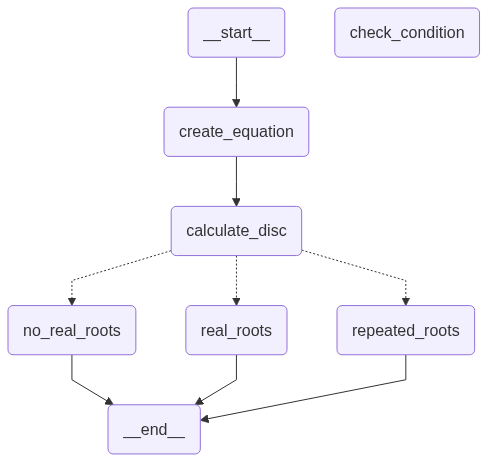

In [28]:
#create a graph object from StateGraph
graph=StateGraph(QuadState)

#define the nodes
graph.add_node('create_equation', create_equation)
graph.add_node('calculate_disc', calculate_disc)
graph.add_node('real_roots', real_roots)
graph.add_node('repeated_roots', repeated_roots)
graph.add_node('no_real_roots', no_real_roots)
graph.add_node('check_condition', check_condition)

#created edges
graph.add_edge(START, 'create_equation')
graph.add_edge('create_equation', 'calculate_disc')
graph.add_conditional_edges('calculate_disc', check_condition)
graph.add_edge('real_roots', END)
graph.add_edge('repeated_roots', END)
graph.add_edge('no_real_roots', END)

workflow=graph.compile()
workflow

In [29]:
initial_state={
    'a': 1,
    'b': -5,
    'c':6,
}

final_state=workflow.invoke(initial_state)

print(final_state['result'])
print(final_state['equation'])

roots are 3.0 and 2.0
1x^2 -5x +6
